<a href="https://colab.research.google.com/github/chawlaniharika23/Fraud_Detection_Research/blob/main/notebooks/04_dynamic_stacking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# ==========================================
# NOTEBOOK 4: DYNAMIC STACKING
# Step 1: Setup and data preparation
# ==========================================

!pip install -q xgboost

import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    confusion_matrix, classification_report
)

from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

# Mount Google Drive
drive.mount("/content/drive")

# Dataset paths
DATA_DIR = "/content/drive/MyDrive/fraud-detection-research/data"

TRANSACTION_PATH = os.path.join(
    DATA_DIR, "train_transaction.csv"
)
IDENTITY_PATH = os.path.join(
    DATA_DIR, "train_identity.csv"
)

# Load transaction data
df = pd.read_csv(TRANSACTION_PATH)

# Merge identity data if available
if os.path.exists(IDENTITY_PATH):
    identity_df = pd.read_csv(IDENTITY_PATH)
    df = df.merge(
        identity_df,
        on="TransactionID",
        how="left"
    )

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

# Select target and features
TARGET = "isFraud"

ieee_candidates = [
    "TransactionDT", "TransactionAmt",
    "card1", "card2", "card3", "card4",
    "card5", "card6", "addr1", "addr2",
    "dist1", "dist2",
    "C1", "C2", "C3", "C4", "C5",
    "C6", "C7", "C8", "C9", "C10",
    "C11", "C12", "C13", "C14"
]

features = [
    col for col in ieee_candidates
    if col in df.columns
]

X = df[features].copy()
y = df[TARGET].astype("int8")

# Remove entirely missing columns
all_missing = X.columns[X.isna().all()].tolist()
X.drop(columns=all_missing, inplace=True)

# Encode categorical columns
for col in X.select_dtypes(
    include=["object", "category"]
).columns:
    X[col] = (
        X[col].astype("category")
        .cat.codes.replace(-1, np.nan)
    )

# Replace infinite values
X = X.replace([np.inf, -np.inf], np.nan)

print("\nFeature preparation completed.")
print("Selected features:", len(X.columns))
print("Feature names:", list(X.columns))
print("Target distribution:")
print(y.value_counts())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset loaded successfully.
Dataset shape: (590540, 434)

Feature preparation completed.
Selected features: 26
Feature names: ['TransactionDT', 'TransactionAmt', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'dist1', 'dist2', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14']
Target distribution:
isFraud
0    569877
1     20663
Name: count, dtype: int64


In [ ]:

# ==========================================
# Step 2: Stratified sampling and splitting
# ==========================================

RANDOM_STATE = 42
SAMPLE_SIZE = 100_000

if len(X) > SAMPLE_SIZE:
    X_sample, _, y_sample, _ = train_test_split(
        X,
        y,
        train_size=SAMPLE_SIZE,
        stratify=y,
        random_state=RANDOM_STATE
    )
else:
    X_sample = X.copy()
    y_sample = y.copy()

X_train, X_test, y_train, y_test = train_test_split(
    X_sample,
    y_sample,
    test_size=0.20,
    stratify=y_sample,
    random_state=RANDOM_STATE
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining fraud cases:", int(y_train.sum()))
print("Testing fraud cases:", int(y_test.sum()))

print(
    "Training fraud rate:",
    round(y_train.mean() * 100, 4), "%"
)
print(
    "Testing fraud rate:",
    round(y_test.mean() * 100, 4), "%"
)


Training shape: (80000, 26)
Testing shape: (20000, 26)

Training fraud cases: 2799
Testing fraud cases: 700
Training fraud rate: 3.4988 %
Testing fraud rate: 3.5 %


In [ ]:

# ==========================================
# Step 3: Define base models and meta-learner
# ==========================================

from sklearn.ensemble import StackingClassifier
from sklearn.model_selection import StratifiedKFold

# Calculate class weight from training data only
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())

scale_pos_weight = negative_count / positive_count

# Logistic Regression
lr_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Random Forest
rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# XGBoost
xgb_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", XGBClassifier(
        n_estimators=400,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="aucpr",
        tree_method="hist",
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        n_jobs=-1
    ))
])

# Define base learners
base_models = [
    ("logistic_regression", lr_model),
    ("random_forest", rf_model),
    ("xgboost", xgb_model)
]

# Define meta-learner
meta_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Stratified 5-fold cross-validation
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Base models defined:")
for name, model in base_models:
    print("-", name)

print("\nMeta-learner: Logistic Regression")
print("Cross-validation: 5-fold StratifiedKFold")
print("XGBoost scale_pos_weight:", round(scale_pos_weight, 2))


Base models defined:
- logistic_regression
- random_forest
- xgboost

Meta-learner: Logistic Regression
Cross-validation: 5-fold StratifiedKFold
XGBoost scale_pos_weight: 27.58


In [ ]:

# ==========================================
# Step 4: Build and train Dynamic Stacking
# ==========================================

stacking_model = StackingClassifier(
    estimators=base_models,
    final_estimator=meta_model,
    stack_method="predict_proba",
    cv=cv_strategy,
    passthrough=False,
    n_jobs=1
)

print("Starting Dynamic Stacking training...")

start_time = time.time()

stacking_model.fit(X_train, y_train)

stacking_training_time = time.time() - start_time

print("\nDynamic Stacking training completed.")
print(
    "Training time:",
    round(stacking_training_time, 2),
    "seconds"
)


Starting Dynamic Stacking training...

Dynamic Stacking training completed.
Training time: 110.81 seconds


In [ ]:

# ==========================================
# Step 5: Evaluate Dynamic Stacking
# ==========================================

# Generate predictions
stack_pred = stacking_model.predict(X_test)

# Generate fraud probabilities
stack_prob = stacking_model.predict_proba(X_test)[:, 1]

# Calculate metrics
stack_results = {
    "Model": "Dynamic Stacking",
    "Precision": precision_score(
        y_test, stack_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, stack_pred, zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, stack_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, stack_prob),
    "PR-AUC (Average Precision)": average_precision_score(
        y_test, stack_prob
    )
}

stack_results_df = pd.DataFrame([stack_results])

print("Dynamic Stacking Evaluation Results:")
display(stack_results_df.round(4))

print("\nClassification Report:")
print(classification_report(
    y_test, stack_pred, zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, stack_pred))


Dynamic Stacking Evaluation Results:


,Model,Precision,Recall,F1-Score,ROC-AUC,PR-AUC (Average Precision)
0,Dynamic Stacking,0.1806,0.7829,0.2934,0.9029,0.5475



Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.87      0.93     19300
           1       0.18      0.78      0.29       700

    accuracy                           0.87     20000
   macro avg       0.59      0.83      0.61     20000
weighted avg       0.96      0.87      0.91     20000


Confusion Matrix:
[[16813  2487]
 [  152   548]]


In [ ]:

# ==========================================
# Step 6: Dynamic Stacking threshold analysis
# ==========================================

thresholds_to_test = [
    0.10, 0.20, 0.30, 0.40,
    0.50, 0.60, 0.70, 0.80
]

stack_threshold_results = []

for threshold in thresholds_to_test:

    threshold_pred = (stack_prob >= threshold).astype(int)

    stack_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, threshold_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, threshold_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, threshold_pred, zero_division=0
        ),
        "Fraud Flagged": int(threshold_pred.sum())
    })

stack_threshold_df = pd.DataFrame(stack_threshold_results)

print("Dynamic Stacking Threshold Comparison:")
display(stack_threshold_df.round(4))


Dynamic Stacking Threshold Comparison:


,Threshold,Precision,Recall,F1-Score,Fraud Flagged
0,0.1,0.0410,0.9929,0.0787,16959
1,0.2,0.0689,0.9386,0.1284,9535
2,0.3,0.1006,0.8886,0.1808,6182
3,0.4,0.1350,0.8214,0.2319,4259
4,0.5,0.1806,0.7829,0.2934,3035
5,0.6,0.2294,0.7329,0.3495,2236
6,0.7,0.2932,0.6757,0.4090,1613
7,0.8,0.3824,0.6157,0.4718,1127


In [ ]:

# ==========================================
# Step 7: Save stacking results
# ==========================================

RESULTS_DIR = (
    "/content/drive/MyDrive/"
    "fraud-detection-research/results"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

# Save evaluation metrics
stack_results_df.to_csv(
    os.path.join(RESULTS_DIR, "stacking_model_results.csv"),
    index=False
)

# Save threshold comparison
stack_threshold_df.to_csv(
    os.path.join(RESULTS_DIR, "stacking_threshold_results.csv"),
    index=False
)

print("Dynamic Stacking results saved successfully.")

print("\nSaved files:")
print("1. stacking_model_results.csv")
print("2. stacking_threshold_results.csv")


Dynamic Stacking results saved successfully.

Saved files:
1. stacking_model_results.csv
2. stacking_threshold_results.csv


In [ ]:

# ==========================================
# Step 9: Prepare Dynamic Classifier Selection
# ==========================================

from sklearn.base import clone
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import balanced_accuracy_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Divide existing training data
X_base_train, X_dsel, y_base_train, y_dsel = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    stratify=y_train,
    random_state=42
)

print("Base training shape:", X_base_train.shape)
print("DSEL shape:", X_dsel.shape)
print("Final testing shape:", X_test.shape)

print("\nBase training fraud cases:", int(y_base_train.sum()))
print("DSEL fraud cases:", int(y_dsel.sum()))
print("Test fraud cases:", int(y_test.sum()))

# Prepare scaled features for nearest-neighbour search
distance_imputer = SimpleImputer(strategy="median")
distance_scaler = StandardScaler()

X_base_distance = distance_imputer.fit_transform(X_base_train)
X_dsel_distance = distance_imputer.transform(X_dsel)
X_test_distance = distance_imputer.transform(X_test)

X_base_distance = distance_scaler.fit_transform(X_base_distance)
X_dsel_distance = distance_scaler.transform(X_dsel_distance)
X_test_distance = distance_scaler.transform(X_test_distance)

# Build nearest-neighbour index using DSEL only
K_NEIGHBORS = 7

neighbor_model = NearestNeighbors(
    n_neighbors=K_NEIGHBORS,
    metric="euclidean",
    n_jobs=-1
)

neighbor_model.fit(X_dsel_distance)

print("\nDynamic selection preparation completed.")
print("Number of local neighbors:", K_NEIGHBORS)


Base training shape: (60000, 26)
DSEL shape: (20000, 26)
Final testing shape: (20000, 26)

Base training fraud cases: 2099
DSEL fraud cases: 700
Test fraud cases: 700

Dynamic selection preparation completed.
Number of local neighbors: 7


In [ ]:

# ==========================================
# Step 10: Train base classifiers for DCS
# ==========================================

dcs_models = {}

for model_name, model in base_models:

    print(f"Training {model_name}...")

    fitted_model = clone(model)
    fitted_model.fit(X_base_train, y_base_train)

    dcs_models[model_name] = fitted_model

    print(f"{model_name} trained successfully.")

print("\nAll DCS base classifiers trained.")


Training logistic_regression...
logistic_regression trained successfully.
Training random_forest...
random_forest trained successfully.
Training xgboost...
xgboost trained successfully.

All DCS base classifiers trained.


In [ ]:

# ==========================================
# Step 11: Dynamic classifier selection
# ==========================================

# Predictions for DSEL and test observations
dsel_predictions = {}
test_predictions = {}
test_probabilities = {}

for model_name, model in dcs_models.items():

    dsel_predictions[model_name] = model.predict(X_dsel)
    test_predictions[model_name] = model.predict(X_test)
    test_probabilities[model_name] = model.predict_proba(X_test)[:, 1]

# Find local neighbours for each test transaction
neighbor_indices = neighbor_model.kneighbors(
    X_test_distance,
    return_distance=False
)

model_names = list(dcs_models.keys())

# Store dynamically selected predictions
dcs_pred = np.zeros(len(X_test), dtype=int)
dcs_prob = np.zeros(len(X_test), dtype=float)
selected_models = []

for i, indices in enumerate(neighbor_indices):

    local_y = y_dsel.iloc[indices].to_numpy()

    local_competence = {}

    for model_name in model_names:

        local_pred = dsel_predictions[model_name][indices]

        local_competence[model_name] = balanced_accuracy_score(
            local_y,
            local_pred
        )

    # Select the locally most competent model
    best_model = max(
        model_names,
        key=lambda name: local_competence[name]
    )

    selected_models.append(best_model)

    # Use the selected model's prediction and probability
    dcs_pred[i] = test_predictions[best_model][i]
    dcs_prob[i] = test_probabilities[best_model][i]

print("Dynamic classifier selection completed.")

print("\nModel selection frequency:")
print(pd.Series(selected_models).value_counts())

print("\nTotal test transactions:", len(dcs_pred))


Dynamic classifier selection completed.

Model selection frequency:
logistic_regression    13236
random_forest           6096
xgboost                  668
Name: count, dtype: int64

Total test transactions: 20000


In [ ]:

# ==========================================
# Step 12: Evaluate Dynamic Classifier Selection
# ==========================================

dcs_results = {
    "Model": "Dynamic Classifier Selection",
    "Precision": precision_score(
        y_test, dcs_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, dcs_pred, zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, dcs_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, dcs_prob),
    "PR-AUC (Average Precision)": average_precision_score(
        y_test, dcs_prob
    )
}

dcs_results_df = pd.DataFrame([dcs_results])

print("Dynamic Classifier Selection Results:")
display(dcs_results_df.round(4))

print("\nClassification Report:")
print(classification_report(
    y_test, dcs_pred, zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dcs_pred))


Dynamic Classifier Selection Results:


,Model,Precision,Recall,F1-Score,ROC-AUC,PR-AUC (Average Precision)
0,Dynamic Classifier Selection,0.3112,0.4957,0.3824,0.7969,0.3808



Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.96      0.97     19300
           1       0.31      0.50      0.38       700

    accuracy                           0.94     20000
   macro avg       0.65      0.73      0.68     20000
weighted avg       0.96      0.94      0.95     20000


Confusion Matrix:
[[18532   768]
 [  353   347]]


In [ ]:

# ==========================================
# Step 13: Final model comparison
# ==========================================

final_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Precision": 0.1358,
        "Recall": 0.6971,
        "F1-Score": 0.2273,
        "ROC-AUC": 0.8459,
        "PR-AUC": 0.3931
    },
    {
        "Model": "Random Forest",
        "Precision": 0.3836,
        "Recall": 0.5343,
        "F1-Score": 0.4466,
        "ROC-AUC": 0.8901,
        "PR-AUC": 0.5081
    },
    {
        "Model": "XGBoost",
        "Precision": 0.2188,
        "Recall": 0.7314,
        "F1-Score": 0.3368,
        "ROC-AUC": 0.8977,
        "PR-AUC": 0.5187
    },
    {
        "Model": "Standard Stacking",
        "Precision": 0.1806,
        "Recall": 0.7829,
        "F1-Score": 0.2934,
        "ROC-AUC": 0.9029,
        "PR-AUC": 0.5475
    },
    {
        "Model": "Dynamic Classifier Selection",
        "Precision": 0.3112,
        "Recall": 0.4957,
        "F1-Score": 0.3824,
        "ROC-AUC": 0.7969,
        "PR-AUC": 0.3808
    }
])

print("Final Model Performance Comparison:")
display(final_comparison.round(4))

# Save comparison
final_comparison.to_csv(
    os.path.join(RESULTS_DIR, "final_model_comparison.csv"),
    index=False
)

print("\nFinal comparison saved successfully.")


Final Model Performance Comparison:


,Model,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.1358,0.6971,0.2273,0.8459,0.3931
1,Random Forest,0.3836,0.5343,0.4466,0.8901,0.5081
2,XGBoost,0.2188,0.7314,0.3368,0.8977,0.5187
3,Standard Stacking,0.1806,0.7829,0.2934,0.9029,0.5475
4,Dynamic Classifier Selection,0.3112,0.4957,0.3824,0.7969,0.3808



Final comparison saved successfully.


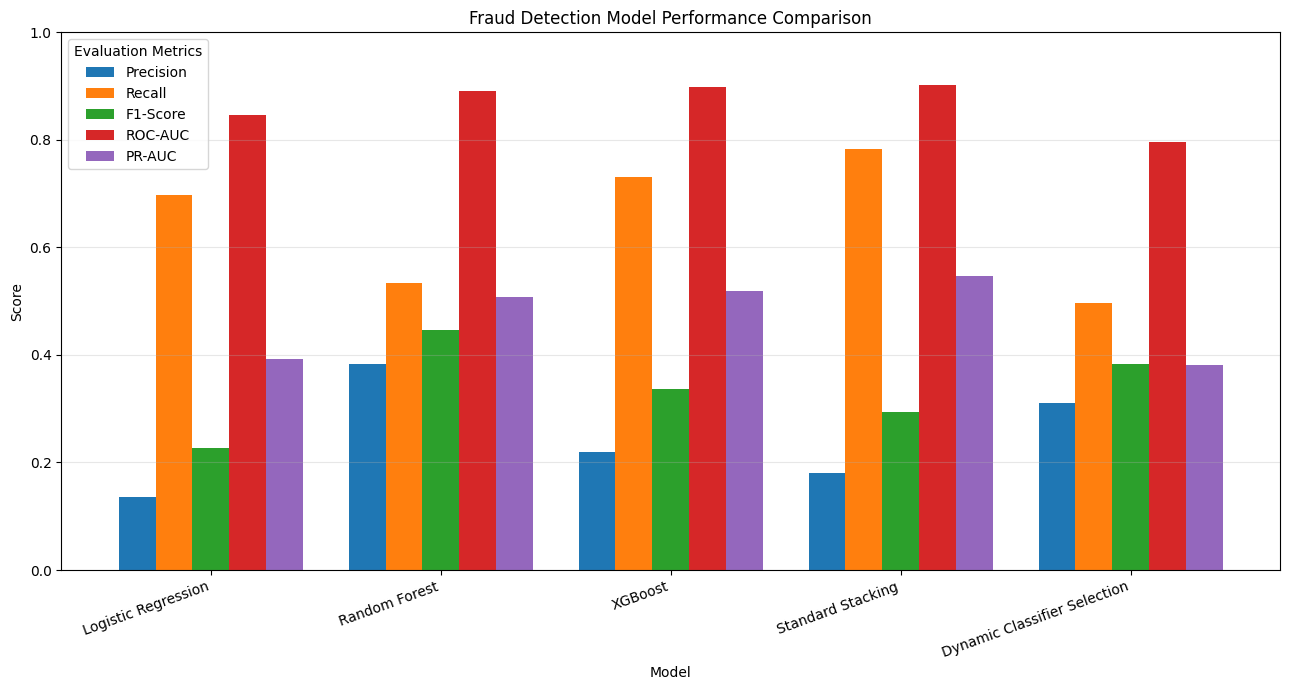

In [ ]:

# ==========================================
# Step 14: Visual comparison
# ==========================================

metrics = [
    "Precision", "Recall", "F1-Score",
    "ROC-AUC", "PR-AUC"
]

ax = final_comparison.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(13, 7),
    width=0.8
)

plt.title("Fraud Detection Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# Save model predictions for Notebook 5

import os
import numpy as np

# Generate individual base-model probabilities
lr_prob = stacking_model.named_estimators_[
    "logistic_regression"
].predict_proba(X_test)[:, 1]

rf_prob = stacking_model.named_estimators_[
    "random_forest"
].predict_proba(X_test)[:, 1]

xgb_prob_final = stacking_model.named_estimators_[
    "xgboost"
].predict_proba(X_test)[:, 1]

# Save all predictions
prediction_path = os.path.join(
    RESULTS_DIR,
    "final_model_predictions.npz"
)

np.savez_compressed(
    prediction_path,
    y_test=np.asarray(y_test),
    logistic_regression_prob=lr_prob,
    random_forest_prob=rf_prob,
    xgboost_prob=xgb_prob_final,
    stacking_prob=stack_prob,
    dcs_prob=dcs_prob,
    dcs_pred=dcs_pred
)

print("Prediction data saved successfully.")
print("Test observations:", len(y_test))


Prediction data saved successfully.
Test observations: 20000
